# Random Forest Regression

A random forest grows many trees, each on a different random sample of the data, and averages their answers. Here it predicts **mpg**, first from **horsepower** alone and then from several inputs.

This notebook goes with the **Random Forest Regression** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

**The steps:** load the data → split → fit → count the trees → try more inputs.

## 1. Load the data

Each row is a car from the late 1970s and early 1980s. We predict `mpg`. A few cars have no horsepower listed, so we drop them first.

The data is the [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) data set from the UCI Machine Learning Repository (CC BY 4.0). See `datasets/README.md` for what we changed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/mpg.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,18.0,8,307.0,130.0,3504,12.0,70,usa
1,15.0,8,350.0,165.0,3693,11.5,70,usa
2,18.0,8,318.0,150.0,3436,11.0,70,usa
3,16.0,8,304.0,150.0,3433,12.0,70,usa
4,17.0,8,302.0,140.0,3449,10.5,70,usa


In [2]:
dataset = dataset.dropna(subset=['horsepower'])
X = dataset[['horsepower']].values
y = dataset['mpg'].values
print(X.shape, 'cars')

(392, 1) cars


## 2. Split into train and test

The model learns from the **training** cars (75%). We hold back the other 25% and only use them at the end. The test score shows how the model does on cars it has never seen. These are the ringed points on the site's boards.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(len(X_train), 'train,', len(X_test), 'test')

294 train, 98 test


## 3. Fit the forest

`n_estimators` is the number of trees. Every tree sees a bootstrap sample (a random draw with repeats) of the training cars. The forest predicts the **average** of its trees. No scaling is needed.

In [4]:
regressor = RandomForestRegressor(n_estimators=100, random_state=0)
regressor.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of

## 4. Check the result

**R²** says how much of the ups and downs in the data the model explains. 1 is perfect, 0 is no better than always guessing the average. The number that matters is the **test** R². The last line shows the typical miss in miles per gallon.

In [5]:
y_pred_train = regressor.predict(X_train)
y_pred_test = regressor.predict(X_test)
print('Train R²:', round(r2_score(y_train, y_pred_train), 3))
print('Test R²: ', round(r2_score(y_test, y_pred_test), 3))
print('Test error on average:', round(mean_absolute_error(y_test, y_pred_test), 2), 'mpg')

Train R²: 0.827
Test R²:  0.649
Test error on average: 3.36 mpg


## 5. How many trees?

One tree is jumpy. Averaging more trees calms it down, until adding more stops helping.

In [6]:
for n in [1, 3, 10, 30, 100, 300]:
    m = RandomForestRegressor(n_estimators=n, random_state=0).fit(X_train, y_train)
    print(f'{n:>3} trees: test R² {r2_score(y_test, m.predict(X_test)):.3f}')

  1 trees: test R² 0.559
  3 trees: test R² 0.639
 10 trees: test R² 0.647
 30 trees: test R² 0.645


100 trees: test R² 0.649


300 trees: test R² 0.648


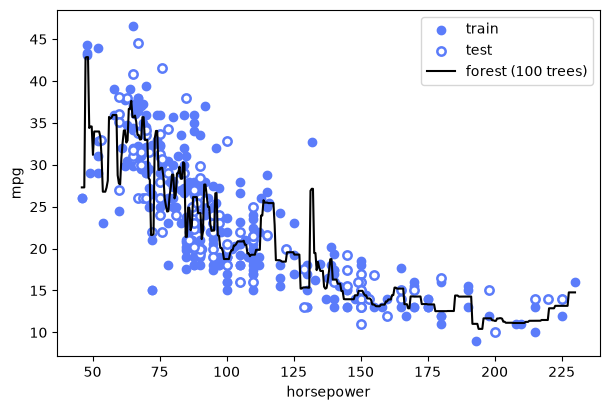

In [7]:
grid = np.linspace(X.min(), X.max(), 400).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_train, y_train, color='#5b7cfa', label='train')
plt.scatter(X_test, y_test, facecolors='white', edgecolors='#5b7cfa', linewidths=1.8, label='test')
plt.plot(grid, regressor.predict(grid), color='black', label='forest (100 trees)')
plt.xlabel('horsepower'); plt.ylabel('mpg'); plt.legend()
plt.show()

## 6. More than one input

A forest handles several inputs without any extra work. Here it uses four, and tells us which ones it relied on most (`feature_importances_`).

In [8]:
features = ['weight', 'horsepower', 'displacement', 'acceleration']
X4_train, X4_test, y4_train, y4_test = train_test_split(dataset[features].values, y, test_size=0.25, random_state=0)
forest4 = RandomForestRegressor(n_estimators=100, random_state=0).fit(X4_train, y4_train)
print('Test R² with four inputs:', round(r2_score(y4_test, forest4.predict(X4_test)), 3))
print(pd.Series(forest4.feature_importances_, index=features).sort_values(ascending=False).round(3))

Test R² with four inputs: 0.735
displacement    0.456
weight          0.309
horsepower      0.173
acceleration    0.062
dtype: float64


## Try this

1. Set `max_depth=3` in the forest. What happens to train and test R²?
2. Ask the forest about a horsepower far outside the data, such as 400. Does the answer keep falling the way a line would?
3. Which input matters most in the four-input forest? Does that match your guess?

## See it: the fit and the misses

**Left:** the fitted curve through the cars. Filled dots are training cars and ringed dots are test cars. The test R² is in the title. **Right:** the residuals, which are the misses (actual mpg minus predicted mpg). **Notice how** the curve is jagged because it follows the training cars closely. The filled dots sit tighter around 0 than the ringed ones: the forest fits the cars it has seen better than the cars it has not.

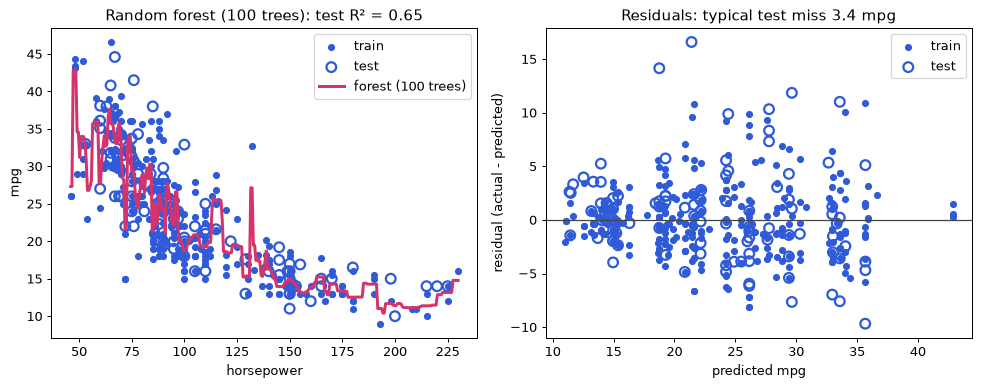

In [9]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

def model_predict(X_raw):
    return regressor.predict(X_raw)

xs = X[:, :1]
fit_x = np.linspace(xs.min(), xs.max(), 300).reshape(-1, 1)
yt, yte = np.ravel(y_train), np.ravel(y_test)
p_tr, p_te = model_predict(X_train), model_predict(X_test)
r2 = r2_score(yte, p_te)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
ax1.scatter(X_train[:, 0], yt, color=BLUE, s=22, label='train')
ax1.scatter(X_test[:, 0], yte, facecolors='none', edgecolors=BLUE, s=60, linewidths=1.8, label='test')
ax1.plot(fit_x[:, 0], model_predict(fit_x), color=PINK, linewidth=2.4, label='forest (100 trees)')
ax1.set_xlabel('horsepower'); ax1.set_ylabel('mpg')
ax1.set_title(f'Random forest (100 trees): test R² = {r2:.2f}')
ax1.legend()

ax2.axhline(0, color='#444444', linewidth=1)
ax2.scatter(p_tr, yt - p_tr, color=BLUE, s=22, label='train')
ax2.scatter(p_te, yte - p_te, facecolors='none', edgecolors=BLUE, s=60, linewidths=1.8, label='test')
ax2.set_xlabel('predicted mpg'); ax2.set_ylabel('residual (actual - predicted)')
ax2.set_title(f'Residuals: typical test miss {np.abs(yte - p_te).mean():.1f} mpg')
ax2.legend()
fig.tight_layout()
plt.show()
